# 04 · Modelul de vulnerabilitate (LightGBM + SHAP)
Explică pierderea observată în 2024 (ținta din `03e`) prin factori structurali, doar pe parcelele arabile. Validare pe blocuri spațiale de 5 km, explicații cu SHAP pe fiecare parcelă.

Rezultatul arată **asocieri, nu cauze dovedite**. Harta-erou arată pierderea observată; scorul de aici e panou secundar, cu R² spațial scris pe slide.

In [1]:
# Sincronizare: aduce repo-ul pe runtime și încarcă configurarea.
# Local (kernel pe PC) găsește direct ../gisday_config.py; pe Colab clonează repo-ul privat.
import os, sys, subprocess, base64, getpass

def _auth(tok):
    b = base64.b64encode(f'x-access-token:{tok}'.encode()).decode()
    return ['-c', f'http.extraheader=AUTHORIZATION: basic {b}']

def _token():
    global TOKEN
    if 'TOKEN' not in globals():
        TOKEN = getpass.getpass('Token GitHub (fine-grained, doar repo-ul gisday2026): ')
    return TOKEN

if not os.path.exists('gisday_config.py'):
    if os.path.exists('../gisday_config.py'):
        os.chdir('..')
    else:
        REPO = 'https://github.com/lefterpatrickandrei-sketch/gisday2026.git'   # același cu GITHUB_REPO din gisday_config.py
        if not os.path.exists('/content/gisday2026'):
            subprocess.run(['git', *_auth(_token()), 'clone', REPO, '/content/gisday2026'], check=True)
        os.chdir('/content/gisday2026')
sys.path.insert(0, os.getcwd())
from gisday_config import *

def pull():
    subprocess.run(['git', *_auth(_token()), 'pull', '--ff-only'], check=True)

def push(paths, msg):
    subprocess.run(['git', 'add', *[str(p) for p in paths]], check=True)
    subprocess.run(['git', '-c', 'user.name=gisday-runtime', '-c', 'user.email=gisday@users.noreply.github.com',
                    'commit', '-m', msg], check=False)
    subprocess.run(['git', *_auth(_token()), 'push'], check=True)

print('Lucrez în', os.getcwd())

Lucrez în C:\Users\lefpa\Downloads\gisday2026\gisday2026


In [2]:
%pip install -q lightgbm shap geopandas pyarrow matplotlib

Note: you may need to restart the kernel to use updated packages.


In [3]:
import geopandas as gpd, pandas as pd, numpy as np, lightgbm as lgb, shap, json
from sklearn.model_selection import GroupKFold
from sklearn.metrics import r2_score, mean_squared_error
parcels = gpd.read_parquet(OUT / 'parcels.parquet')
F = pd.read_parquet(OUT / 'parcel_features.parquet')
T = pd.read_parquet(OUT / 'parcel_target.parquet')          # ținta din 03e: z-score HR-VPP TPROD 2024 vs 2017–2023
D = parcels.merge(F, on='parcel_id').merge(T, on='parcel_id')
for name in ('parcel_canals', 'parcel_wind'):               # factorii din 03f și 03c
    if (OUT / f'{name}.parquet').exists():
        D = D.merge(pd.read_parquet(OUT / f'{name}.parquet'), on='parcel_id')
TARGET = D.loss_source.iloc[0]
D = D[D.is_arable & D['loss'].notna()].copy()               # doar parcele arabile cu țintă (>= 5 ani de bază)
D['tip_cultura_2024_num'] = D['tip_cultura_2024'].map({'primavara': 0, 'neclasificat': 1, 'toamna': 2})
print('ținta:', TARGET, '| parcele:', len(D))
print(D['loss'].describe(percentiles=[.01, .05, .25, .5, .75, .95, .99]).round(3).to_string())

C:\Users\lefpa\Downloads\gisday2026\gisday2026\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


ținta: hrvpp_tprod_z | parcele: 13237
count    13237.000
mean         0.462
std          1.537
min        -14.177
1%          -4.601
5%          -2.205
25%         -0.199
50%          0.676
75%          1.371
95%          2.429
99%          3.491
max         19.903


In [4]:
# Factori structurali permiși (PAS C1–C2): nimic din vara 2024 și fără irrigated_prob în modelul principal.
CANDIDATES = ['elev', 'slope', 'soc_sg_top', 'sand_sg_top', 'clay_sg_top', 'soc_lucas_model',
              'wind_exposure', 'dist_canal_m', 'dist_network_m', 'area_ha',
              'tip_cultura_2024_num', 'tprod_mean_2017_2023']
FEATURES = [c for c in CANDIDATES if c in D.columns]
print('factori:', FEATURES)
D = D.dropna(subset=['loss'] + FEATURES).copy()
c = D.geometry.centroid
D['block'] = (c.x // 5000).astype(int).astype(str) + '_' + (c.y // 5000).astype(int).astype(str)
X, y = D[FEATURES], D['loss']
print('parcele în model:', len(D), '| blocuri de 5 km:', D['block'].nunique())

factori: ['elev', 'slope', 'soc_sg_top', 'sand_sg_top', 'clay_sg_top', 'wind_exposure', 'dist_canal_m', 'dist_network_m', 'area_ha', 'tip_cultura_2024_num', 'tprod_mean_2017_2023']
parcele în model: 13230 | blocuri de 5 km: 82


In [5]:
params = dict(n_estimators=600, learning_rate=0.03, num_leaves=31, min_child_samples=30,
              subsample=0.8, subsample_freq=1, colsample_bytree=0.8, random_state=2024, verbose=-1)
pred = np.zeros(len(D))
pred_base = np.zeros(len(D))
fold_r2, fold_rmse = [], []
for k, (tr, te) in enumerate(GroupKFold(n_splits=5).split(X, y, D['block'])):
    m = lgb.LGBMRegressor(**params).fit(X.iloc[tr], y.iloc[tr])
    pred[te] = m.predict(X.iloc[te])
    pred_base[te] = y.iloc[tr].mean()
    r2_k = float(r2_score(y.iloc[te], pred[te]))
    rmse_k = float(mean_squared_error(y.iloc[te], pred[te]) ** 0.5)
    fold_r2.append(round(r2_k, 3)); fold_rmse.append(round(rmse_k, 3))
    print(f'fold {k}: R2={r2_k:.3f}, RMSE={rmse_k:.3f}')
r2_by_group = {g: round(float(r2_score(y[D.tip_cultura_2024 == g], pred[D.tip_cultura_2024 == g])), 3)
               for g in ('toamna', 'primavara', 'neclasificat') if (D.tip_cultura_2024 == g).sum() > 10}
metrics = dict(target=TARGET, r2_spatial=round(float(r2_score(y, pred)), 3),
               r2_folds_mean=round(float(np.mean(fold_r2)), 3), fold_r2=fold_r2,
               rmse=round(float(mean_squared_error(y, pred) ** 0.5), 4),
               rmse_folds_mean=round(float(np.mean(fold_rmse)), 4), fold_rmse=fold_rmse,
               r2_baseline_mean=round(float(r2_score(y, pred_base)), 4),
               rmse_baseline_mean=round(float(mean_squared_error(y, pred_base) ** 0.5), 4),
               r2_by_group=r2_by_group,
               n_parcels=len(D), n_blocks=int(D['block'].nunique()), factors=FEATURES)
print('validare spațială:', metrics)
(OUT / 'model_metrics.json').write_text(json.dumps(metrics, indent=1), encoding='utf-8')

fold 0: R2=0.124, RMSE=1.361


fold 1: R2=0.244, RMSE=1.366


fold 2: R2=0.164, RMSE=1.302


fold 3: R2=0.145, RMSE=1.452


fold 4: R2=0.222, RMSE=1.459
validare spațială: {'target': 'hrvpp_tprod_z', 'r2_spatial': 0.183, 'r2_folds_mean': 0.18, 'fold_r2': [0.124, 0.244, 0.164, 0.145, 0.222], 'rmse': 1.3889, 'rmse_folds_mean': 1.388, 'fold_rmse': [1.361, 1.366, 1.302, 1.452, 1.459], 'r2_baseline_mean': -0.0004, 'rmse_baseline_mean': 1.5374, 'r2_by_group': {'toamna': 0.022, 'primavara': 0.048, 'neclasificat': -0.065}, 'n_parcels': 13230, 'n_blocks': 82, 'factors': ['elev', 'slope', 'soc_sg_top', 'sand_sg_top', 'clay_sg_top', 'wind_exposure', 'dist_canal_m', 'dist_network_m', 'area_ha', 'tip_cultura_2024_num', 'tprod_mean_2017_2023']}


643

In [6]:
model = lgb.LGBMRegressor(**params).fit(X, y)
sv = shap.TreeExplainer(model).shap_values(X)
S = pd.DataFrame(sv, columns=[f'shap_{f}' for f in FEATURES], index=D.index)
D['id'] = D['parcel_id']
D['loss_pred'] = pred
D['pred_loss'] = pred
D['vuln_score'] = (D['loss_pred'].rank(pct=True) * 100).round(1)          # 0–100 (percentila pierderii prezise)
D['factor_dominant'] = S.idxmax(axis=1).str.replace('shap_', '', regex=False)
D['driver'] = D['factor_dominant']
D = pd.concat([D, S], axis=1)
cols = ['id', 'parcel_id', 'area_ha', 'loss', 'loss_pred', 'pred_loss', 'vuln_score',
        'factor_dominant', 'driver', 'tip_cultura_2024'] + list(S.columns) + ['geometry']
R = gpd.GeoDataFrame(D[cols], geometry='geometry', crs=CRS)
R.to_parquet(OUT / 'vulnerability.parquet')
R.to_file(OUT / 'vulnerability.gpkg', layer='vulnerabilitate', driver='GPKG')
print(R['factor_dominant'].value_counts())

factor_dominant
tip_cultura_2024_num    6883
tprod_mean_2017_2023    1209
clay_sg_top             1152
dist_network_m           991
elev                     928
sand_sg_top              611
dist_canal_m             379
slope                    305
soc_sg_top               273
wind_exposure            252
area_ha                  247
Name: count, dtype: int64


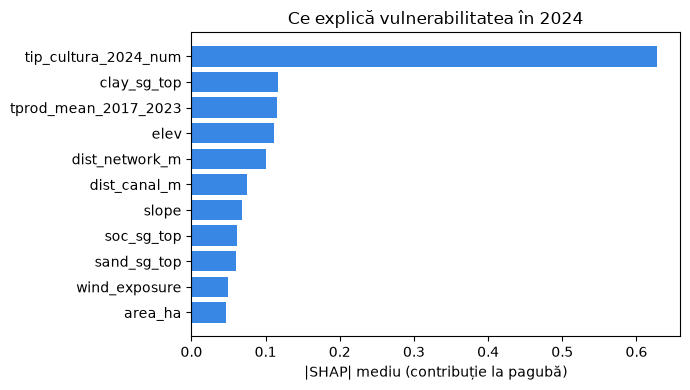

In [7]:
import matplotlib.pyplot as plt
imp = S.abs().mean().sort_values()
imp.index = imp.index.str.replace('shap_', '', regex=False)
fig, ax = plt.subplots(figsize=(7, 4))
ax.barh(imp.index, imp.values, color='#3987e5')
ax.set_xlabel('|SHAP| mediu (contribuție la pagubă)')
ax.set_title('Ce explică vulnerabilitatea în 2024')
plt.tight_layout(); plt.savefig(OUT / 'shap_importance.png', dpi=200); plt.show()

In [8]:
if os.path.exists('/content'):     # pe PC comiți normal, din git
    push([OUT / 'vulnerability.parquet', OUT / 'vulnerability.gpkg', OUT / 'shap_importance.png'], 'model vulnerabilitate')